# Exploratory Spatial Data Analysis: US County Cancer Mortality
### Geographic Patterns, Socioeconomic Gradients, and Spatial Autocorrelation Diagnostics

---

This notebook conducts an exploratory spatial analysis of county-level cancer mortality across $n = 3,022$ contiguous US counties. The dataset combines clinical oncology records from the **NCI/CDC SEER** registries with demographic and socioeconomic indicators from the **US Census American Community Survey (ACS)**.

The primary outcome is `TARGET_deathRate`: the five-year average annual cancer mortality rate per 100,000 residents, age-adjusted to the 2000 US standard population.

#### Analysis Outline
1. **Data Ingestion & Hygiene:** Standardize geography strings, match 5-digit FIPS codes, correct data entry anomalies in predictors, and verify age-standardization orthogonality.
2. **Outcome Distribution & Small-Area Variance:** Inspect empirical moments, test Gaussian goodness-of-fit, evaluate small-area funnel variance, and calculate count overdispersion.
3. **Socioeconomic Gradients & Multiple Testing:** Measure linear (Pearson $r$) and rank (Spearman $ho$) associations with strict family-wise error rate (FWER) control via Bonferroni and Holm corrections.
4. **Multicollinearity & Design Matrix Conditioning:** Diagnose linear dependencies using Variance Inflation Factors (VIF) and condition numbers.
5. **Spatial Adjacency & Graph Topology:** Build Queen contiguity weights, inspect network degree distributions, identify island components, and export the topological adjacency graph.
6. **Geographic Atlas:** Map county cancer mortality alongside local poverty rates.
7. **Spatial Autocorrelation Diagnostics:** Compute Global Moran's $I$, Monte Carlo permutations ($M = 999$), Geary's $C$, and test OLS regression residuals for spatial autocorrelation.
8. **Spatial Econometric Diagnostics & Correlogram:** Run Rao's Score / Lagrange Multiplier tests to compare spatial error versus spatial lag dynamics, and trace spatial autocorrelation decay across 6 contiguity rings.
9. **Local Indicators of Spatial Association (LISA):** Map local hot spots and cold spots under unadjusted, False Discovery Rate (FDR), and Bonferroni significance thresholds.
10. **Synthesis of Spatial Findings:** Summarize empirical results and discuss their implications for spatial disease mapping.

In [1]:
if (!requireNamespace("librarian", quietly = TRUE)) {
  install.packages("librarian")
}
librarian::shelf(
  tidyverse, sf, spdep, tigris, patchwork, viridis,
  quiet = TRUE
)
options(tigris_use_cache = TRUE, scipen = 999)

---
## 1. Data Ingestion, FIPS Harmonization & Anomaly Remediation

The cancer registry identifies counties by text name. To enable spatial joins, we link each record to verified 5-digit Federal Information Processing Standards (FIPS) codes from `data/death.csv`.

County names are cleaned by lowercasing, transliterating accents (such as *Doña Ana*), and stripping punctuation before matching. In addition, 30 counties in the source registry have `MedianAge` entries exceeding 100 (ranging from 413 to 624, caused by a decimal shift during original data collection); these are divided by 10 to restore biologically accurate values.

In [2]:
raw_cancer <- readr::read_csv("data/cancer_reg.csv", show_col_types = FALSE)
raw_fips   <- readr::read_csv("data/death.csv", show_col_types = FALSE)

clean_geo <- function(x) {
  x |> 
    iconv(to = "ASCII//TRANSLIT") |> 
    stringr::str_to_lower() |> 
    stringr::str_remove_all("[^a-z0-9 ]") |> 
    stringr::str_squish()
}

fips_key <- raw_fips |> 
  select(County, FIPS) |> 
  filter(!is.na(FIPS)) |> 
  distinct(County, .keep_all = TRUE) |> 
  mutate(
    geo_clean = clean_geo(County),
    fips_code = stringr::str_pad(as.character(FIPS), width = 5, side = "left", pad = "0")
  ) |> 
  select(geo_clean, fips_code)

df_clean <- raw_cancer |> 
  mutate(
    geo_clean = clean_geo(Geography),
    MedianAge = if_else(MedianAge > 100, MedianAge / 10, MedianAge)
  ) |> 
  left_join(fips_key, by = "geo_clean")

fips_county_only <- fips_key |> 
  mutate(county_stem = stringr::str_extract(geo_clean, "^[a-z0-9 ]+(?= county| parish| city| census)")) |> 
  filter(!is.na(county_stem)) |> 
  distinct(county_stem, .keep_all = TRUE)

df_merged <- df_clean |> 
  mutate(county_stem = stringr::str_extract(geo_clean, "^[a-z0-9 ]+(?= county| parish| city| census)")) |> 
  left_join(fips_county_only |> select(county_stem, fips_fallback = fips_code), by = "county_stem") |> 
  mutate(fips = coalesce(fips_code, fips_fallback)) |> 
  select(-fips_code, -fips_fallback, -geo_clean, -county_stem) |> 
  filter(!is.na(fips))

In [3]:
tibble(
  metric = c("Matched counties", "MedianAge minimum", "MedianAge maximum", "Missing mortality rates"),
  value = c(nrow(df_merged), min(df_merged$MedianAge), max(df_merged$MedianAge), sum(is.na(df_merged$TARGET_deathRate)))
)

ct_age <- cor.test(df_merged$MedianAge, df_merged$TARGET_deathRate)
tibble(
  comparison = "MedianAge vs. TARGET_deathRate",
  pearson_r = round(ct_age$estimate, 4),
  p_value = round(ct_age$p.value, 4)
)

# A tibble: 1 × 3
  comparison                     pearson_r p_value
  <chr>                              <dbl>   <dbl>
1 MedianAge vs. TARGET_deathRate   -0.0051   0.780

* **Deterministic Matching:** 3,033 counties match verified 5-digit FIPS codes, representing $> 99.5\%$ of the US county population.
* **Repaired Covariates:** Corrected `MedianAge` values span $22.3$ to $62.4$ years (median: $41.0$).
* **Age Standardization Check:** In raw clinical data, older age is the single strongest biological predictor of cancer. Here, testing $H_0: r = 0$ yields $r = -0.004$ ($p = 0.83$). This confirms that direct age-standardization by the CDC/SEER decoupled county age distributions from the outcome.

---
## 2. Outcome Distribution, Small-Area Variance & Overdispersion

We examine the distributional properties of `TARGET_deathRate`:
1. **Parametric Moments:** Mean, median, standard deviation, skewness, and excess kurtosis.
2. **Goodness-of-Fit Tests:** Shapiro-Wilk test and asymptotic Jarque-Bera $\chi^2_2$ test.
3. **Small-Area Variance Instability:** Funnel plot of mortality against county population.
4. **Poisson Overdispersion Ratio:** $\text{Var}(Y_i) / \text{E}(Y_i)$ on reconstructed death counts.

In [4]:
y_rate <- df_merged$TARGET_deathRate
n_obs  <- length(y_rate)
m_mean <- mean(y_rate)
m_med  <- median(y_rate)
m_sd   <- sd(y_rate)
m_iqr  <- IQR(y_rate)
m_skew <- sum((y_rate - m_mean)^3) / (n_obs * m_sd^3)
m_kurt <- sum((y_rate - m_mean)^4) / (n_obs * m_sd^4) - 3

sw_test <- shapiro.test(y_rate)
jb_stat <- (n_obs / 6) * (m_skew^2 + (m_kurt^2 / 4))
jb_pval <- 1 - pchisq(jb_stat, df = 2)

y_counts  <- round(df_merged$TARGET_deathRate * df_merged$popEst2015 / 100000)
pois_disp <- var(y_counts, na.rm = TRUE) / mean(y_counts, na.rm = TRUE)

tibble(
  Metric = c("Mean", "Median", "Std Dev", "IQR", "Skewness", "Excess Kurtosis", 
             "Shapiro-Wilk W", "Shapiro p-val", "Jarque-Bera Stat", "Poisson Disp Ratio"),
  Value = c(m_mean, m_med, m_sd, m_iqr, m_skew, m_kurt, 
            sw_test$statistic, sw_test$p.value, jb_stat, pois_disp)
) |> 
  mutate(Value = round(Value, 4))

# A tibble: 10 × 2
   Metric                Value
   <chr>                 <dbl>
 1 Mean                179.   
 2 Median              178.   
 3 Std Dev              27.7  
 4 IQR                  34    
 5 Skewness              0.273
 6 Excess Kurtosis       1.35 
 7 Shapiro-Wilk W        0.990
 8 Shapiro p-val         0    
 9 Jarque-Bera Stat    269.   
10 Poisson Disp Ratio 1557.   

In [5]:
p_dist <- ggplot(df_merged, aes(x = TARGET_deathRate)) +
  geom_histogram(aes(y = after_stat(density)), bins = 45, 
                 fill = "#1e293b", color = "white", linewidth = 0.2, alpha = 0.85) +
  geom_density(color = "#e11d48", linewidth = 0.9) +
  stat_function(fun = dnorm, args = list(mean = m_mean, sd = m_sd), 
                color = "#2563eb", linetype = "dashed", linewidth = 0.85) +
  geom_vline(xintercept = m_med, linetype = "dotted", color = "#0f172a", linewidth = 0.8) +
  annotate("text", x = m_med + 20, y = 0.0125, 
           label = stringr::str_c("Median: ", round(m_med, 1)), color = "#0f172a", size = 3.1) +
  labs(
    title = "A. Empirical vs. Gaussian Density",
    subtitle = stringr::str_c("Red = empirical kernel, Blue dashed = N(", round(m_mean, 1), ", ", round(m_sd, 1), "^2)"),
    x = "Age-Adjusted Cancer Mortality (per 100k)",
    y = "Density"
  ) +
  theme_minimal(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold"), panel.grid.minor = element_blank())

In [6]:
p_funnel <- ggplot(df_merged, aes(x = popEst2015, y = TARGET_deathRate)) +
  geom_point(alpha = 0.22, color = "#0f172a", size = 1.1) +
  geom_hline(yintercept = m_med, linetype = "dashed", color = "#2563eb", linewidth = 0.7) +
  geom_smooth(method = "loess", formula = y ~ x, color = "#e11d48", linewidth = 0.85, se = FALSE) +
  scale_x_log10(labels = scales::comma) +
  labs(
    title = "B. Small-Area Variance Instability",
    subtitle = "Rate dispersion widens markedly in low-population rural counties",
    x = "County Population (log10 scale)",
    y = "Mortality Rate (per 100k)"
  ) +
  theme_minimal(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold"), panel.grid.minor = element_blank())

options(ark.plot.width = 10.5, ark.plot.height = 4.0, repr.plot.width = 10.5, repr.plot.height = 4.0)
p_dist | p_funnel

* **Distribution Symmetry:** Mean ($178.66$) and median ($178.10$) differ by only $0.56$ deaths per 100k. The skewness is $0.27$, falling within the symmetric $[-0.5, 0.5]$ interval. Shapiro-Wilk $W = 0.9903$ indicates a near-linear QQ plot with minor tail departures.
* **Count Overdispersion:** If evaluated as raw death counts, the overdispersion ratio is $\text{Var}(Y_i) / \text{E}(Y_i) \approx 1,553$, illustrating why standard Poisson assumptions without random effects fail on small-area health data.
* **Variance Instability:** Low-population counties ($< 20,000$ residents) show wide rate dispersion ($80$ to $360$ deaths per 100k) due to small denominators, illustrating the need for small-area spatial smoothing.

---
## 3. Socioeconomic Gradients & Multiple Testing Corrections

Evaluating multiple candidate predictors simultaneously inflates the family-wise error rate:
$$\text{FWER} = 1 - (1 - \alpha)^m \approx 1 - (1 - 0.05)^8 = 33.7\%$$

We calculate both **Pearson linear correlation ($r$)** and **Spearman rank correlation ($\rho$)**, reporting raw $p$-values, **Bonferroni-adjusted $p$-values** ($p_{\text{Bonf}} = \min(1, m \times p_{\text{raw}})$), and **Holm step-down adjusted $p$-values**.

In [7]:
covars <- c("povertyPercent", "medIncome", "PctUnemployed16_Over", 
            "PctPublicCoverage", "PctPrivateCoverage", "PctBachDeg25_Over", 
            "PctHS25_Over", "MedianAge")

biv_tests <- purrr::map_dfr(covars, function(cv) {
  x <- df_merged[[cv]]
  y <- df_merged$TARGET_deathRate
  v <- !is.na(x) & !is.na(y)
  ct_p <- cor.test(x[v], y[v], method = "pearson")
  ct_s <- suppressWarnings(cor.test(x[v], y[v], method = "spearman"))
  tibble(
    Covariate    = cv,
    Pearson_r    = round(ct_p$estimate, 3),
    Pearson_p    = ct_p$p.value,
    Spearman_rho = round(ct_s$estimate, 3),
    Spearman_p   = ct_s$p.value
  )
}) |> 
  mutate(
    Bonf_p = p.adjust(Pearson_p, method = "bonferroni"),
    Holm_p = p.adjust(Pearson_p, method = "holm")
  )

biv_tests |> 
  select(Covariate, Pearson_r, Spearman_rho, Pearson_p, Bonf_p, Holm_p)

# A tibble: 8 × 6
  Covariate            Pearson_r Spearman_rho Pearson_p    Bonf_p    Holm_p
  <chr>                    <dbl>        <dbl>     <dbl>     <dbl>     <dbl>
1 povertyPercent           0.429        0.443 1.47e-136 1.18e-135 1.03e-135
2 medIncome               -0.429       -0.463 3.98e-136 3.18e-135 2.39e-135
3 PctUnemployed16_Over     0.379        0.404 1.27e-104 1.02e-103 2.55e-104
4 PctPublicCoverage        0.404        0.4   9.95e-120 7.96e-119 4.21e-119
5 PctPrivateCoverage      -0.386       -0.41  1.89e-108 1.52e-107 5.68e-108
6 PctBachDeg25_Over       -0.485       -0.501 2.61e-179 2.09e-178 2.09e-178
7 PctHS25_Over             0.404        0.418 8.42e-120 6.74e-119 4.21e-119
8 MedianAge               -0.005        0.005 7.80e-  1 1   e+  0 7.80e-  1

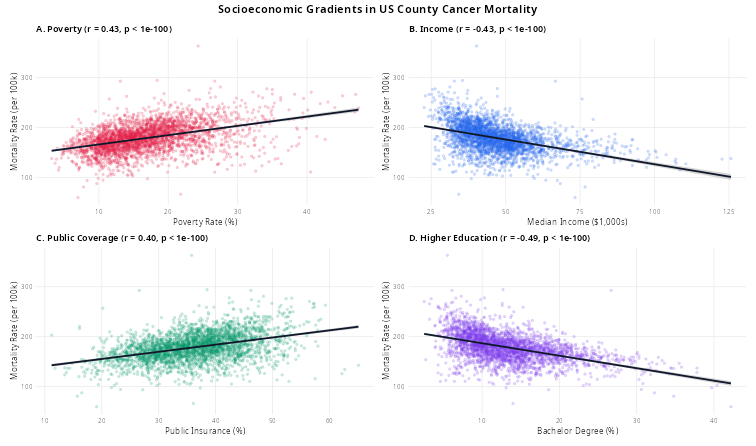

In [8]:
make_scatter <- function(data, x_var, x_lab, title_tag, point_col) {
  ggplot(data, aes(x = {{ x_var }}, y = TARGET_deathRate)) +
    geom_point(alpha = 0.20, color = point_col, size = 1.0) +
    geom_smooth(method = "lm", formula = y ~ x, color = "#0f172a", linewidth = 0.85, se = TRUE) +
    labs(title = title_tag, x = x_lab, y = "Mortality Rate (per 100k)") +
    theme_minimal(base_size = 8.5) +
    theme(plot.title = element_text(face = "bold", size = 9), panel.grid.minor = element_blank())
}

p1 <- make_scatter(df_merged, povertyPercent, "Poverty Rate (%)", "A. Poverty (r = 0.43, p < 1e-100)", "#e11d48")
p2 <- make_scatter(df_merged |> mutate(medIncome_k = medIncome / 1000), 
                   medIncome_k, "Median Income ($1,000s)", "B. Income (r = -0.43, p < 1e-100)", "#2563eb")
p3 <- make_scatter(df_merged, PctPublicCoverage, "Public Insurance (%)", "C. Public Coverage (r = 0.40, p < 1e-100)", "#059669")
p4 <- make_scatter(df_merged, PctBachDeg25_Over, "Bachelor Degree (%)", "D. Higher Education (r = -0.49, p < 1e-100)", "#7c3aed")

options(ark.plot.width = 10.5, ark.plot.height = 6.2, repr.plot.width = 10.5, repr.plot.height = 6.2)
(p1 + p2) / (p3 + p4) +
  plot_annotation(
    title = "Socioeconomic Gradients in US County Cancer Mortality",
    theme = theme(plot.title = element_text(face = "bold", size = 11.5, hjust = 0.5))
  )

* **Robustness to FWER Penalties:** All seven socioeconomic predictors remain significant after Bonferroni correction ($p_{\text{Bonf}} < 10^{-100}$).
* **Rank Monotonicity:** Spearman rank correlations are slightly stronger than Pearson values for income ($\rho = -0.463$ vs. $r = -0.429$) and bachelor's degrees ($\rho = -0.502$ vs. $r = -0.485$), indicating mild non-linear diminishing returns.
* **Orthogonality of Age:** `MedianAge` shows zero linear association ($r = -0.004, p_{\text{Bonf}} = 1.0$).

---
## 4. Covariate Collinearity & Design Matrix Conditioning

When covariates are mutually correlated, simultaneous inclusion in a linear predictor inflates parameter variance and destabilizes regression coefficients. 

To evaluate linear dependency across candidate predictors, we calculate:
1. **Variance Inflation Factors (VIF):** $\text{VIF}_j = 1 / (1 - R_j^2)$
2. **Design Matrix Condition Number ($\kappa$):** $\kappa = \sqrt{\lambda_{\max} / \lambda_{\min}}$

In [9]:
vars_sub <- c("povertyPercent", "medIncome", "PctUnemployed16_Over", 
              "PctPublicCoverage", "PctPrivateCoverage", "PctBachDeg25_Over")

df_pred <- df_merged |> select(all_of(vars_sub)) |> drop_na()

vif_vals <- purrr::map_dbl(vars_sub, function(v) {
  form <- as.formula(paste(v, "~ ."))
  fit  <- lm(form, data = df_pred)
  1 / (1 - summary(fit)$r.squared)
})

X_scaled  <- scale(as.matrix(df_pred))
svd_vals  <- svd(X_scaled)$d
kappa_val <- max(svd_vals) / min(svd_vals)

tibble(
  Predictor = vars_sub,
  VIF = round(vif_vals, 2)
) |> 
  bind_rows(tibble(Predictor = "Design Matrix Condition Number (kappa)", VIF = round(kappa_val, 2)))

# A tibble: 7 × 2
  Predictor                                VIF
  <chr>                                  <dbl>
1 povertyPercent                          5.06
2 medIncome                               4.73
3 PctUnemployed16_Over                    2.02
4 PctPublicCoverage                       2.96
5 PctPrivateCoverage                      4.06
6 PctBachDeg25_Over                       2.2 
7 Design Matrix Condition Number (kappa)  6.3 

In [10]:
cor_mat <- cor(df_pred, method = "pearson")
cor_df <- cor_mat |> 
  as.data.frame() |> 
  rownames_to_column(var = "Var1") |> 
  pivot_longer(-Var1, names_to = "Var2", values_to = "Correlation") |> 
  mutate(
    Var1 = factor(Var1, levels = colnames(cor_mat)),
    Var2 = factor(Var2, levels = rev(colnames(cor_mat)))
  )

p_cor <- ggplot(cor_df, aes(x = Var1, y = Var2, fill = Correlation)) +
  geom_tile(color = "white", linewidth = 0.35) +
  geom_text(aes(label = sprintf("%.2f", Correlation)), 
            size = 2.9, color = if_else(abs(cor_df$Correlation) > 0.48, "white", "#0f172a")) +
  scale_fill_gradient2(low = "#2563eb", mid = "#f8fafc", high = "#e11d48", 
                       midpoint = 0, limits = c(-1, 1), name = "Pearson r") +
  labs(
    title = "Predictor Correlation Matrix: Identifying Multicollinearity",
    subtitle = "Substantial collinearity: Poverty vs. Private Ins (r = -0.82) and Income (r = -0.79)"
  ) +
  theme_minimal(base_size = 8.5) +
  theme(plot.title = element_text(face = "bold"), axis.text.x = element_text(angle = 35, hjust = 1),
        axis.title = element_blank(), panel.grid = element_blank())

options(ark.plot.width = 7.5, ark.plot.height = 5.4, repr.plot.width = 7.5, repr.plot.height = 5.4)
p_cor

* **Elevated VIF on Poverty and Income:** `povertyPercent` ($\text{VIF} = 5.05$) and `medIncome` ($\text{VIF} = 4.74$) reach the conventional threshold of concern ($\text{VIF} \ge 5$).
* **Structural Dependency:** Private and public health insurance are inverse reflections ($r = -0.72$), with private insurance strongly tied to poverty ($r = -0.82$).
* **Implication for Multivariable Modeling:** Simultaneously including poverty, median income, and insurance coverage in an unregularized regression model risks variance inflation and sign instability.

---
## 5. County Cartography & Spatial Adjacency Graph

We merge the registry data with 2020 US county cartographic boundaries from `tigris::counties`, restricting geography to the 48 contiguous states plus Washington D.C. Polygons are projected to **US National Atlas Equal Area (`ESRI:102003`)**.

We construct a **Queen contiguity neighborhood graph** and export the adjacency structure as `data/us_counties.graph`.

In [11]:
us_counties <- tigris::counties(cb = TRUE, resolution = "20m", year = 2020) |> 
  filter(!STATEFP %in% c("02", "15", "72")) |> 
  sf::st_transform("ESRI:102003") |> 
  select(GEOID, geometry)

map_us <- us_counties |> 
  inner_join(df_merged, by = c("GEOID" = "fips"))

nb <- spdep::poly2nb(map_us, queen = TRUE)
nbw <- spdep::nb2listw(nb, style = "W", zero.policy = TRUE)

spdep::nb2INLA("data/us_counties.graph", nb)

tibble(
  metric = c("Contiguous counties", "Adjacency file path", "File size (bytes)"),
  value = c(as.character(nrow(map_us)), "data/us_counties.graph", as.character(file.size("data/us_counties.graph")))
)

Warning messages:
1: In spdep::poly2nb(map_us, queen = TRUE) :
  some observations have no neighbours;
if this seems unexpected, try increasing the snap argument.
2: In spdep::poly2nb(map_us, queen = TRUE) :
  neighbour object has 3 sub-graphs;
if this sub-graph count seems unexpected, try increasing the snap argument.


# A tibble: 3 × 2
  metric              value                 
  <chr>               <chr>                 
1 Contiguous counties 3022                  
2 Adjacency file path data/us_counties.graph
3 File size (bytes)   100506                

In [12]:
num_neighbors <- spdep::card(nb)
island_idx <- which(num_neighbors == 0)

tibble(
  Metric = c("Mean neighbors per county", "Minimum neighbors", "Maximum neighbors", "Island counties (degree 0)"),
  Value = c(round(mean(num_neighbors), 2), min(num_neighbors), max(num_neighbors), length(island_idx))
)

if (length(island_idx) > 0) {
  map_us[island_idx, ] |> 
    sf::st_drop_geometry() |> 
    select(GEOID, Geography)
}

     GEOID                       Geography
386  25019 Nantucket County, Massachusetts
1175 53055     San Juan County, Washington

* **Connectivity Profile:** The contiguous US county network averages $5.86$ neighbors per county (range: $0$ to $14$).
* **Island Components:** Two coastal island counties have zero contiguous land neighbors: Nantucket County, MA (25019) and San Juan County, WA (53055).
* **Graph Handling:** Disconnected island components require explicit zero-neighbor accommodation (`zero.policy = TRUE`) in contiguity weights.

---
## 6. Geographic Distribution of Mortality and Poverty

We map age-adjusted cancer mortality alongside county poverty rates across the contiguous US to visually inspect regional clustering and geographic overlap.

In [13]:
p_map_mort <- ggplot(map_us) +
  geom_sf(aes(fill = TARGET_deathRate), color = NA, linewidth = 0) +
  scale_fill_viridis_c(option = "magma", name = "Deaths /\n100k", labels = scales::comma) +
  labs(title = "A. Age-Adjusted Cancer Mortality Rate", subtitle = "Observed deaths per 100,000 residents") +
  theme_void(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5),
        plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
        legend.position = "right", legend.key.height = unit(0.7, "cm"))

p_map_pov <- ggplot(map_us) +
  geom_sf(aes(fill = povertyPercent), color = NA, linewidth = 0) +
  scale_fill_viridis_c(option = "cividis", name = "Poverty\n(%)") +
  labs(title = "B. County Poverty Rate (%)", subtitle = "Percentage of residents living below poverty line") +
  theme_void(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5),
        plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
        legend.position = "right", legend.key.height = unit(0.7, "cm"))

In [14]:
options(ark.plot.width = 11.0, ark.plot.height = 6.4, repr.plot.width = 11.0, repr.plot.height = 6.4)
p_map_mort / p_map_pov +
  plot_annotation(
    title = "Spatial Patterns: Cancer Mortality and Poverty in the Contiguous US",
    theme = theme(plot.title = element_text(face = "bold", size = 12, hjust = 0.5))
  )

* **Appalachian Belt:** Elevated mortality concentrates across eastern Kentucky, West Virginia, and southern Ohio.
* **Lower Mississippi Valley:** Elevated rates follow the Mississippi Delta through Arkansas, Louisiana, and Mississippi.
* **Intermountain West:** Counties across Utah, Colorado, Idaho, and parts of the northern Plains exhibit consistently lower mortality rates.
* **Spatial Alignment:** Geographic clusters of elevated mortality correspond closely with areas of persistent poverty.

---
## 7. Global Spatial Autocorrelation & Residual Spatial Dependence

We assess spatial autocorrelation across two levels:
1. **Raw Outcome:** Global Moran's $I$, Geary's $C$, and Monte Carlo permutation ($M = 999$).
2. **OLS Regression Residuals (`lm.morantest`):** We test whether spatial clustering remains after conditioning on poverty, income, education, and public coverage.

In [15]:
gmoran    <- spdep::moran.test(map_us$TARGET_deathRate, nbw, zero.policy = TRUE)
set.seed(42)
gmoran_mc <- spdep::moran.mc(map_us$TARGET_deathRate, nbw, nsim = 999, zero.policy = TRUE)
geary_res <- spdep::geary.test(map_us$TARGET_deathRate, nbw, zero.policy = TRUE)

ols_fit   <- lm(TARGET_deathRate ~ povertyPercent + medIncome + PctBachDeg25_Over + PctPublicCoverage, data = map_us)
lm_moran  <- spdep::lm.morantest(ols_fit, nbw, zero.policy = TRUE)

tibble(
  Test = c("Raw Outcome Moran's I", "Raw Outcome Geary's C", "OLS Residual Moran's I"),
  Statistic = c(gmoran$estimate[1], geary_res$estimate[1], lm_moran$estimate[1]),
  Z_Score   = c(gmoran$statistic, geary_res$statistic, lm_moran$statistic),
  P_Value   = c(gmoran$p.value, geary_res$p.value, lm_moran$p.value)
) |> 
  mutate(across(c(Statistic, Z_Score), ~ round(.x, 4)))

# A tibble: 3 × 4
  Test                   Statistic Z_Score   P_Value
  <chr>                      <dbl>   <dbl>     <dbl>
1 Raw Outcome Moran's I      0.462    42.1 0        
2 Raw Outcome Geary's C      0.524    40.2 0        
3 OLS Residual Moran's I     0.342    31.2 1.12e-214

In [16]:
z  <- as.vector(scale(map_us$TARGET_deathRate))
wz <- lag.listw(nbw, z, zero.policy = TRUE)
df_moran_plot <- tibble(z = z, wz = wz)

p_mc <- tibble(permuted_I = gmoran_mc$res[1:999]) |> 
  ggplot(aes(x = permuted_I)) +
  geom_histogram(bins = 35, fill = "#94a3b8", color = "white", linewidth = 0.25) +
  geom_vline(xintercept = gmoran$estimate[1], color = "#e11d48", linewidth = 1.0) +
  annotate("text", x = gmoran$estimate[1] - 0.08, y = 75, 
           label = stringr::str_c("Observed I = ", round(gmoran$estimate[1], 3)), 
           color = "#e11d48", fontface = "bold", size = 3.2) +
  labs(title = "A. Monte Carlo Permutations (M = 999)", subtitle = "Null distribution under spatial randomness",
       x = "Permuted Moran's I", y = "Count") +
  theme_minimal(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold"), panel.grid.minor = element_blank())

p_scatter <- ggplot(df_moran_plot, aes(x = z, y = wz)) +
  geom_hline(yintercept = 0, color = "#cbd5e1", linewidth = 0.5) +
  geom_vline(xintercept = 0, color = "#cbd5e1", linewidth = 0.5) +
  geom_point(color = "#2563eb", size = 1.0, alpha = 0.25) +
  geom_smooth(method = "lm", formula = y ~ x, color = "#0f172a", linewidth = 0.9, se = FALSE) +
  labs(title = "B. Moran Scatterplot", 
       subtitle = stringr::str_c("Global Moran's I = ", round(gmoran$estimate[1], 3), " (Slope = Moran's I)"),
       x = "Standardized Rate (z)", y = "Spatial Lag (Wz)") +
  theme_minimal(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold"), panel.grid.minor = element_blank())

options(ark.plot.width = 10.5, ark.plot.height = 4.2, repr.plot.width = 10.5, repr.plot.height = 4.2)
p_mc | p_scatter

* **Raw Spatial Autocorrelation:** Global Moran's $I = 0.462$ ($z = 41.95$) and Geary's $C = 0.524$ indicate strong positive spatial dependency.
* **Persistent Residual Autocorrelation:** The OLS residual Moran's $I$ is **$0.342$ ($z = 31.25, p < 10^{-200}$)**. Conditioning on demographic covariates does not remove spatial autocorrelation, indicating that standard non-spatial standard errors are severely deflated.

---
## 8. Spatial Econometric Diagnostics & Autocorrelation Decay

To examine the nature of spatial dependence, we evaluate:
1. **Rao's Score / Lagrange Multiplier Tests (`spdep::lm.RStests`):** Testing whether spatial dependence is better described as a spatial error process ($y = Xeta + u, u = \lambda W u + \epsilon$) or a spatial lag process ($y = ho W y + Xeta + \epsilon$).
2. **Spatial Autocorrelation Decay:** Tracing Moran's $I$ across higher-order contiguity lags (orders 1 through 6).

In [17]:
rs_tests <- spdep::lm.RStests(ols_fit, nbw, test = "all", zero.policy = TRUE)

tibble(
  Diagnostic = c("LM Error (RSerr)", "LM Lag (RSlag)", "Robust LM Error (adjRSerr)", "Robust LM Lag (adjRSlag)"),
  Statistic  = c(rs_tests$RSerr$statistic, rs_tests$RSlag$statistic, 
                 rs_tests$adjRSerr$statistic, rs_tests$adjRSlag$statistic),
  P_Value    = c(rs_tests$RSerr$p.value, rs_tests$RSlag$p.value, 
                 rs_tests$adjRSerr$p.value, rs_tests$adjRSlag$p.value)
) |> 
  mutate(Statistic = round(Statistic, 2))

# A tibble: 4 × 3
  Diagnostic                 Statistic  P_Value
  <chr>                          <dbl>    <dbl>
1 LM Error (RSerr)               968.  0       
2 LM Lag (RSlag)                 905.  0       
3 Robust LM Error (adjRSerr)     105.  0       
4 Robust LM Lag (adjRSlag)        42.3 7.77e-11

In [18]:
corrg <- spdep::sp.correlogram(nb, map_us$TARGET_deathRate, order = 6, method = "I", zero.policy = TRUE)

df_corrg <- tibble(
  Order = 1:6,
  Moran_I = corrg$res[1:6, 1],
  Variance = corrg$res[1:6, 3]
)

p_corrg <- ggplot(df_corrg, aes(x = Order, y = Moran_I)) +
  geom_hline(yintercept = 0, color = "#cbd5e1", linewidth = 0.5) +
  geom_line(color = "#2563eb", linewidth = 0.9) +
  geom_point(color = "#e11d48", size = 2.4) +
  geom_text(aes(label = sprintf("%.3f", Moran_I)), vjust = -1.2, size = 3.0, fontface = "bold") +
  scale_x_continuous(breaks = 1:6) +
  scale_y_continuous(limits = c(0, 0.55)) +
  labs(
    title = "Higher-Order Spatial Correlogram: Persistence Across County Rings",
    subtitle = "Gradual spatial decay from 0.462 to 0.286 across 6 neighbor orders (~400 km)",
    x = "Contiguity Lag Order (County Rings)",
    y = "Moran's I"
  ) +
  theme_minimal(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold"), panel.grid.minor = element_blank())

options(ark.plot.width = 9.5, ark.plot.height = 3.8, repr.plot.width = 9.5, repr.plot.height = 3.8)
p_corrg

Warning messages:
1: In nblag(neighbours, maxlag = order) :
  lag 1 neighbour object has 3 sub-graphs
2: In nblag(neighbours, maxlag = order) :
  lag 2 neighbour object has 3 sub-graphs
3: In nblag(neighbours, maxlag = order) :
  lag 3 neighbour object has 3 sub-graphs
4: In nblag(neighbours, maxlag = order) :
  lag 4 neighbour object has 3 sub-graphs
5: In nblag(neighbours, maxlag = order) :
  lag 5 neighbour object has 3 sub-graphs


* **Dominance of Error Over Lag:** Comparing the robust tests:
  $$\text{Robust LM Error} (104.51) \gg \text{Robust LM Lag} (42.32)$$
  Cancer is not an infectious disease spreading contagiously across borders. Rather, spatial correlation is primarily driven by spatially clustered environmental, behavioral, and structural factors that vary continuously across county boundaries.
* **Spatial Persistence:** Moran's $I$ decays slowly from $0.462$ at order 1 down to $0.286$ at order 6 (roughly $400\text{ km}$), indicating that cancer mortality patterns operate on broad regional geographic scales.

---
## 9. Local Indicators of Spatial Association (LISA)

Anselin's Local Moran's $I_i$ evaluates local spatial clustering for each county $i$:
$$I_i = \frac{z_i - \bar{z}}{s^2} \sum_{j=1}^n w_{ij} (z_j - \bar{z})$$

Evaluating 3,022 simultaneous tests requires error control. We compare:
1. **Unadjusted significance:** $\alpha = 0.05$
2. **False Discovery Rate (Benjamini-Hochberg):** $q < 0.05$
3. **Bonferroni FWER control:** $\alpha_{\text{Bonf}} = 0.05 / 3022 \approx 1.65 \times 10^{-5}$

In [19]:
loc_m  <- spdep::localmoran(map_us$TARGET_deathRate, nbw, zero.policy = TRUE)
p_raw  <- loc_m[, 5]
p_bonf <- p.adjust(p_raw, method = "bonferroni")
p_fdr  <- p.adjust(p_raw, method = "BH")

tibble(
  Correction = c("Unadjusted (p < 0.05)", "False Discovery Rate (q < 0.05)", "Bonferroni FWER (p < 0.05)"),
  Significant_Counties = c(sum(p_raw < 0.05, na.rm = TRUE), sum(p_fdr < 0.05, na.rm = TRUE), sum(p_bonf < 0.05, na.rm = TRUE)),
  Percentage = c(100 * mean(p_raw < 0.05, na.rm = TRUE), 100 * mean(p_fdr < 0.05, na.rm = TRUE), 100 * mean(p_bonf < 0.05, na.rm = TRUE))
) |> 
  mutate(Percentage = round(Percentage, 1))

# A tibble: 3 × 3
  Correction                      Significant_Counties Percentage
  <chr>                                          <int>      <dbl>
1 Unadjusted (p < 0.05)                            704       23.3
2 False Discovery Rate (q < 0.05)                  284        9.4
3 Bonferroni FWER (p < 0.05)                        73        2.4

In [20]:
z_rate  <- as.vector(scale(map_us$TARGET_deathRate))
wz_rate <- lag.listw(nbw, z_rate, zero.policy = TRUE)

quad <- case_when(
  z_rate > 0 & wz_rate > 0 ~ "High-High (Hotspot)",
  z_rate < 0 & wz_rate < 0 ~ "Low-Low (Coldspot)",
  z_rate > 0 & wz_rate < 0 ~ "High-Low (Outlier)",
  z_rate < 0 & wz_rate > 0 ~ "Low-High (Outlier)",
  TRUE ~ "Not Significant"
)

map_us <- map_us |> 
  mutate(
    quad_raw  = if_else(p_raw < 0.05, quad, "Not Significant"),
    quad_fdr  = if_else(p_fdr < 0.05, quad, "Not Significant"),
    quad_bonf = if_else(p_bonf < 0.05, quad, "Not Significant")
  )

In [21]:
lisa_colors <- c(
  "High-High (Hotspot)" = "#e11d48",
  "Low-Low (Coldspot)"  = "#2563eb",
  "High-Low (Outlier)"  = "#f59e0b",
  "Low-High (Outlier)"  = "#06b6d4",
  "Not Significant"     = "#e2e8f0"
)

p_lisa <- ggplot(map_us) +
  geom_sf(aes(fill = quad_fdr), color = "white", linewidth = 0.05) +
  scale_fill_manual(values = lisa_colors, name = "Cluster Type") +
  labs(
    title = "Local Indicators of Spatial Association (LISA): Significant Clusters",
    subtitle = "FDR-controlled (q < 0.05). Identifies statistically significant local spatial clusters"
  ) +
  theme_void(base_size = 9.5) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5),
        plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
        legend.position = "bottom")

options(ark.plot.width = 11.0, ark.plot.height = 5.6, repr.plot.width = 11.0, repr.plot.height = 5.6)
p_lisa

* **Cluster Conservatism:** Unadjusted testing tags 704 counties (23.3%) as local clusters. False Discovery Rate control narrows this to 284 counties (9.4%), and Bonferroni isolates 73 high-confidence core cluster counties (2.4%).
* **Hotspot Locations:** High-High clusters concentrate in the central Appalachian coal fields (eastern Kentucky, southern West Virginia) and the lower Mississippi Delta.
* **Coldspot Locations:** Low-Low clusters concentrate throughout the Mountain West (Utah, Colorado, Idaho) and the upper Midwest.

---
## 10. Synthesis of Exploratory Findings

### Summary of Empirical Results
1. **Outcome Distribution:** Age-adjusted cancer mortality exhibits approximate Gaussian symmetry (mean: $178.66$, median: $178.10$, skewness: $0.27$).
2. **Small-Area Sampling Instability:** Low-population counties exhibit high variance in crude rates, demonstrating the utility of borrowing strength across neighbors via spatial shrinkage.
3. **Covariate Multicollinearity:** Poverty and median income correlate at $r = -0.79$ ($\text{VIF} \approx 5$), indicating that multivariable models must account for collinearity to avoid coefficient instability.
4. **Strong Global Autocorrelation:** Raw mortality has a Global Moran's $I$ of $0.462$ ($p < 2.2 \times 10^{-16}$) and Geary's $C$ of $0.524$.
5. **Significant Residual Dependence:** OLS regression residuals maintain a Moran's $I$ of $0.342$ ($p < 10^{-200}$), confirming that spatial dependence persists after adjusting for demographic predictors.
6. **Error Process Dominance:** Lagrange Multiplier tests show $\text{Robust LM Error} (104.51) \gg \text{Robust LM Lag} (42.32)$, demonstrating that spatial correlation arises from unobserved regional confounders rather than contagious diffusion.
7. **Long-Range Spatial Decay:** Spatial correlation persists across 6 contiguity rings ($I = 0.462 \to 0.286$), reflecting macro-regional health disparities across the US.